# 🥑 Visualisasi Data Harga & Volume Penjualan Alpukat (Avocado)

Notebook ini mengimplementasikan beberapa teknik **Data Visualization** yang disesuaikan dengan karakteristik dataset `avocado_clean.csv`:

| No | Teknik | Tujuan |
|----|--------|--------|
| 1 | Histogram | Melihat distribusi harga & volume |
| 2 | Bar Chart | Membandingkan kategori (tipe, wilayah, level geografis) |
| 3 | Boxplot & Violin Plot | Membandingkan sebaran + mendeteksi outlier |
| 4 | Scatter Plot | Hubungan harga vs volume |
| 5 | Line Chart | Tren harga & volume per minggu |
| 6 | Heatmap | Korelasi antar variabel & pola harga wilayah × waktu |
| 7 | Stacked Bar / Pie | Komposisi ukuran (PLU) dan jenis kemasan (bags) |
| 8 | Pairplot & Plotly interaktif | Eksplorasi lanjutan |

**Cara pakai di Google Colab:** jalankan sel dari atas ke bawah. Saat sel *Load Data* dijalankan, upload file `avocado_clean.csv`.

## 1. Import Library & Pengaturan Tampilan

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

# Pengaturan tampilan global
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 100,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
})

# Warna konsisten untuk tipe alpukat
PALETTE = {"conventional": "#3B6EA5", "organic": "#5A9E4B"}

## 2. Load Dataset

In [2]:
# Opsi A (disarankan di Colab): upload file secara manual
try:
    from google.colab import files
    uploaded = files.upload()          # pilih avocado_clean.csv
    nama_file = list(uploaded.keys())[0]
except ImportError:
    # Jika dijalankan di luar Colab (mis. Jupyter lokal)
    nama_file = "avocado_clean.csv"

# Opsi B (jika file ada di Google Drive):
# from google.colab import drive
# drive.mount('/content/drive')
# nama_file = '/content/drive/MyDrive/avocado_clean.csv'

df = pd.read_csv(nama_file, parse_dates=["date"])
print(f"Jumlah baris : {df.shape[0]}")
print(f"Jumlah kolom : {df.shape[1]}")
df.head()

Saving avocado_clean.csv to avocado_clean.csv
Jumlah baris : 2178
Jumlah kolom : 20


,date,average_price,total_volume,plu_4046_small,plu_4225_large,plu_4770_xlarge,total_bags,small_bags,large_bags,xlarge_bags,avocado_type,year,region,volume_mismatch,geo_level,price_outlier,volume_outlier,month,quarter,week_of_year
0,2015-01-04,1.22,40873.28,2819.50,28287.42,49.90,9716.46,9186.93,529.53,0.0,conventional,2015,Albany,False,city_market,False,False,1,1,1
1,2015-01-11,1.24,41195.08,1002.85,31640.34,127.12,8424.77,8036.04,388.73,0.0,conventional,2015,Albany,False,city_market,False,False,1,1,2
2,2015-01-18,1.17,44511.28,914.14,31540.32,135.77,11921.05,11651.09,269.96,0.0,conventional,2015,Albany,False,city_market,False,False,1,1,3
3,2015-01-25,1.06,45147.50,941.38,33196.16,164.14,10845.82,10103.35,742.47,0.0,conventional,2015,Albany,False,city_market,False,False,1,1,4
4,2015-02-01,0.99,70873.60,1353.90,60017.20,179.32,9323.18,9170.82,152.36,0.0,conventional,2015,Albany,False,city_market,False,False,2,1,5


## 3. Pemahaman Dataset (Data Understanding)

In [ ]:
df.info()

In [ ]:
# Statistik deskriptif kolom numerik
df.describe().T.round(2)

In [3]:
# Pengecekan missing value & duplikasi
print("Missing value per kolom:")
print(df.isna().sum()[df.isna().sum() > 0] if df.isna().any().any() else "Tidak ada missing value ✅")
print("\nJumlah baris duplikat:", df.duplicated().sum())

# Ringkasan kolom kategorikal
for kol in ["avocado_type", "geo_level", "volume_mismatch", "price_outlier", "volume_outlier"]:
    print(f"\n{kol}:")
    print(df[kol].value_counts())

print("\nRentang tanggal :", df["date"].min().date(), "s.d.", df["date"].max().date())
print("Jumlah minggu   :", df["date"].nunique())
print("Jumlah region   :", df["region"].nunique())

Missing value per kolom:
Tidak ada missing value ✅

Jumlah baris duplikat: 0

avocado_type:
avocado_type
conventional    1089
organic         1089
Name: count, dtype: int64

geo_level:
geo_level
city_market    1736
region          402
national         40
Name: count, dtype: int64

volume_mismatch:
volume_mismatch
False    2178
Name: count, dtype: int64

price_outlier:
price_outlier
False    2163
True       15
Name: count, dtype: int64

volume_outlier:
volume_outlier
False    2043
True      135
Name: count, dtype: int64

Rentang tanggal : 2015-01-04 s.d. 2015-05-24
Jumlah minggu   : 21
Jumlah region   : 54


In [4]:
df_city = df[df["geo_level"] == "city_market"].copy()
df_nat  = df[df["geo_level"] == "national"].copy()
print("city_market:", len(df_city), "baris | national:", len(df_nat), "baris")

city_market: 1736 baris | national: 40 baris


## 4. Histogram — Distribusi Data

Histogram dipakai untuk variabel numerik kontinu seperti harga dan volume.

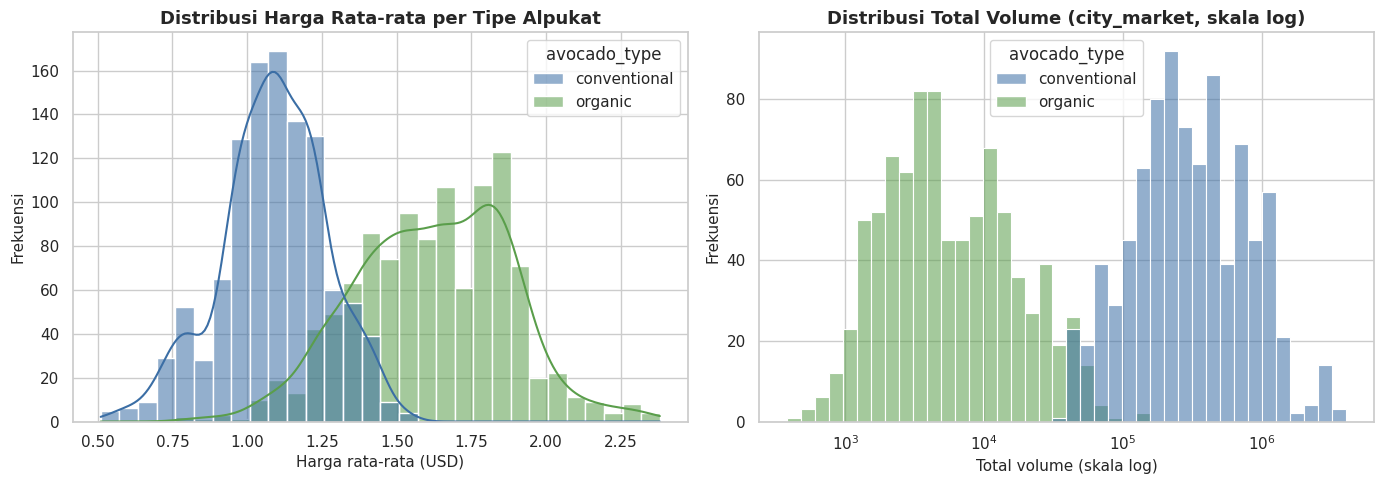

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# (a) Distribusi harga rata-rata per tipe
sns.histplot(data=df, x="average_price", hue="avocado_type", bins=30, kde=True,
             palette=PALETTE, alpha=0.55, ax=axes[0])
axes[0].set_title("Distribusi Harga Rata-rata per Tipe Alpukat")
axes[0].set_xlabel("Harga rata-rata (USD)")
axes[0].set_ylabel("Frekuensi")

# (b) Distribusi total volume (skala log karena sangat skewed)
sns.histplot(data=df_city, x="total_volume", hue="avocado_type", bins=40, log_scale=True,
             palette=PALETTE, alpha=0.55, ax=axes[1])
axes[1].set_title("Distribusi Total Volume (city_market, skala log)")
axes[1].set_xlabel("Total volume (skala log)")
axes[1].set_ylabel("Frekuensi")

plt.tight_layout()
plt.show()

**Cara membaca:** histogram harga memperlihatkan apakah kedua tipe alpukat memiliki rentang harga yang tumpang-tindih atau terpisah. Histogram volume memakai skala log agar sebaran antar-kota yang ukurannya sangat berbeda tetap terbaca.

## 5. Bar Chart — Perbandingan Kategori

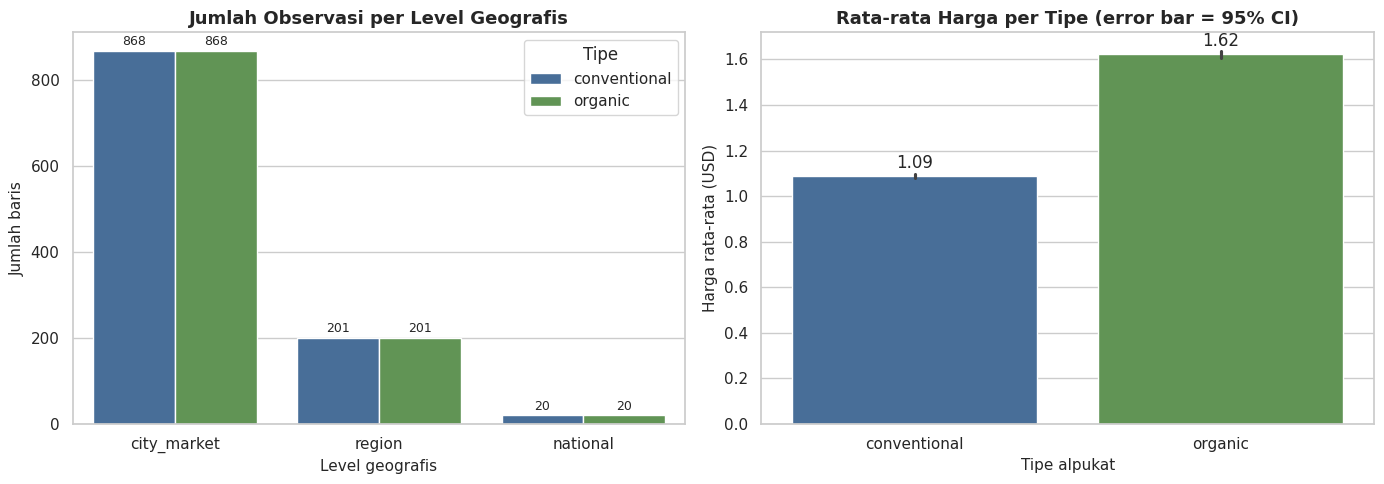

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# (a) Jumlah observasi per level geografis
urut = df["geo_level"].value_counts().index
sns.countplot(data=df, x="geo_level", order=urut, hue="avocado_type",
              palette=PALETTE, ax=axes[0])
axes[0].set_title("Jumlah Observasi per Level Geografis")
axes[0].set_xlabel("Level geografis")
axes[0].set_ylabel("Jumlah baris")
axes[0].legend(title="Tipe")
for c in axes[0].containers:
    axes[0].bar_label(c, padding=2, fontsize=9)

# (b) Rata-rata harga per tipe (+ error bar 95% CI)
sns.barplot(data=df, x="avocado_type", y="average_price", hue="avocado_type",
            palette=PALETTE, errorbar=("ci", 95), legend=False, ax=axes[1])
axes[1].set_title("Rata-rata Harga per Tipe (error bar = 95% CI)")
axes[1].set_xlabel("Tipe alpukat")
axes[1].set_ylabel("Harga rata-rata (USD)")
for c in axes[1].containers:
    axes[1].bar_label(c, fmt="%.2f", padding=3)

plt.tight_layout()
plt.show()

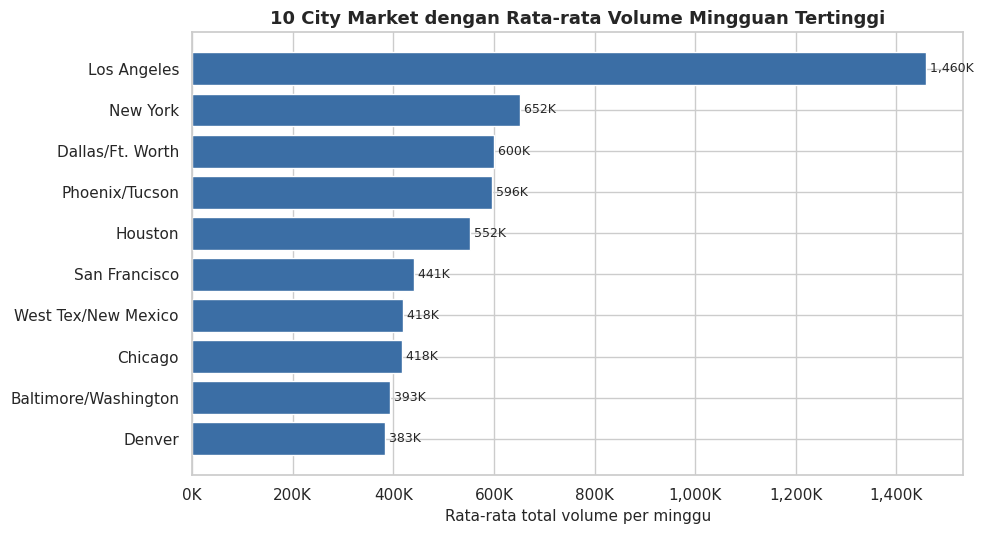

In [7]:
# Top 10 city market berdasarkan total volume mingguan rata-rata (horizontal bar)
top_vol = (df_city.groupby("region")["total_volume"].mean()
           .sort_values(ascending=False).head(10).sort_values())

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(top_vol.index, top_vol.values, color="#3B6EA5")
ax.set_title("10 City Market dengan Rata-rata Volume Mingguan Tertinggi")
ax.set_xlabel("Rata-rata total volume per minggu")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1e3:,.0f}K"))
for i, v in enumerate(top_vol.values):
    ax.text(v, i, f" {v/1e3:,.0f}K", va="center", fontsize=9)
plt.tight_layout()
plt.show()

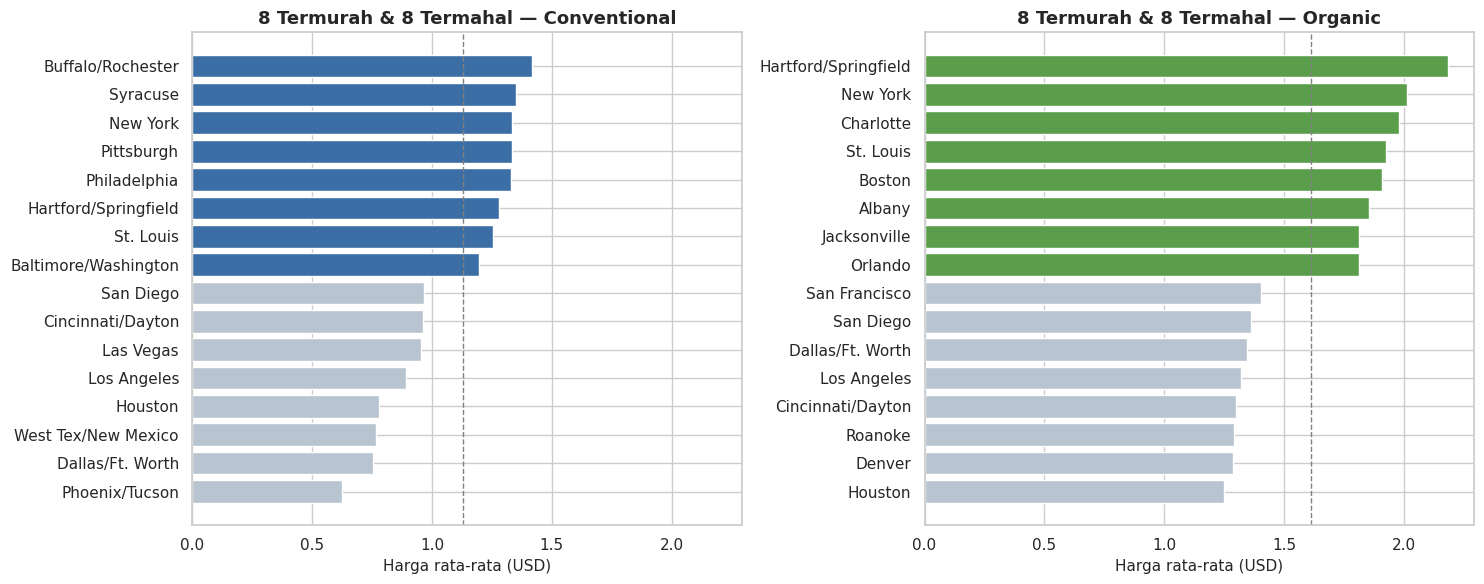

In [8]:
# Harga rata-rata termahal vs termurah (10 teratas & 10 terbawah) per tipe
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharex=True)
for ax, tipe in zip(axes, ["conventional", "organic"]):
    harga = (df_city[df_city["avocado_type"] == tipe]
             .groupby("region")["average_price"].mean().sort_values())
    pilih = pd.concat([harga.head(8), harga.tail(8)])
    warna = [PALETTE[tipe] if v >= harga.median() else "#B8C4D0" for v in pilih.values]
    ax.barh(pilih.index, pilih.values, color=warna)
    ax.axvline(harga.median(), color="gray", ls="--", lw=1)
    ax.set_title(f"8 Termurah & 8 Termahal — {tipe.capitalize()}")
    ax.set_xlabel("Harga rata-rata (USD)")
plt.tight_layout()
plt.show()

## 6. Visualisasi Komposisi — Ukuran Alpukat (PLU) & Jenis Kemasan (Bags)

Kolom `plu_4046_small`, `plu_4225_large`, `plu_4770_xlarge` adalah volume per ukuran, sedangkan `small_bags`, `large_bags`, `xlarge_bags` adalah volume per jenis kemasan.

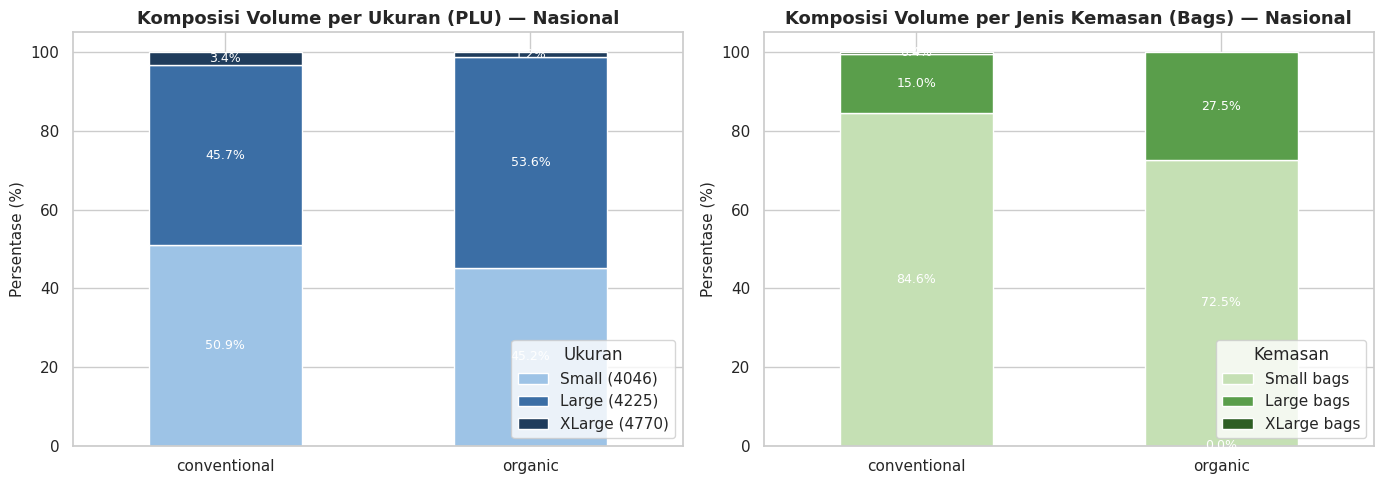

In [9]:
plu_cols = ["plu_4046_small", "plu_4225_large", "plu_4770_xlarge"]
bag_cols = ["small_bags", "large_bags", "xlarge_bags"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# (a) Komposisi PLU per tipe (100% stacked bar)
plu_share = df_nat.groupby("avocado_type")[plu_cols].sum()
plu_share = plu_share.div(plu_share.sum(axis=1), axis=0) * 100
plu_share.plot(kind="bar", stacked=True, ax=axes[0],
               color=["#9DC3E6", "#3B6EA5", "#1F3C5C"], rot=0)
axes[0].set_title("Komposisi Volume per Ukuran (PLU) — Nasional")
axes[0].set_xlabel("")
axes[0].set_ylabel("Persentase (%)")
axes[0].legend(["Small (4046)", "Large (4225)", "XLarge (4770)"], title="Ukuran", loc="lower right")
for c in axes[0].containers:
    axes[0].bar_label(c, fmt="%.1f%%", label_type="center", color="white", fontsize=9)

# (b) Komposisi jenis kemasan per tipe
bag_share = df_nat.groupby("avocado_type")[bag_cols].sum()
bag_share = bag_share.div(bag_share.sum(axis=1), axis=0) * 100
bag_share.plot(kind="bar", stacked=True, ax=axes[1],
               color=["#C5E0B4", "#5A9E4B", "#2E5E24"], rot=0)
axes[1].set_title("Komposisi Volume per Jenis Kemasan (Bags) — Nasional")
axes[1].set_xlabel("")
axes[1].set_ylabel("Persentase (%)")
axes[1].legend(["Small bags", "Large bags", "XLarge bags"], title="Kemasan", loc="lower right")
for c in axes[1].containers:
    axes[1].bar_label(c, fmt="%.1f%%", label_type="center", color="white", fontsize=9)

plt.tight_layout()
plt.show()

In [ ]:
# Pie chart: proporsi volume penjualan conventional vs organic (nasional)
vol_tipe = df_nat.groupby("avocado_type")["total_volume"].sum()

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.pie(vol_tipe.values, labels=[t.capitalize() for t in vol_tipe.index],
       colors=[PALETTE[t] for t in vol_tipe.index], autopct="%1.1f%%", startangle=90,
       wedgeprops=dict(width=0.45, edgecolor="white"), textprops=dict(fontsize=11))
ax.set_title("Proporsi Total Volume Nasional: Conventional vs Organic")
plt.show()

## 7. Boxplot & Violin Plot — Sebaran dan Outlier

Boxplot menampilkan median, kuartil, dan titik outlier. Dataset ini juga memiliki flag `price_outlier` dan `volume_outlier`.

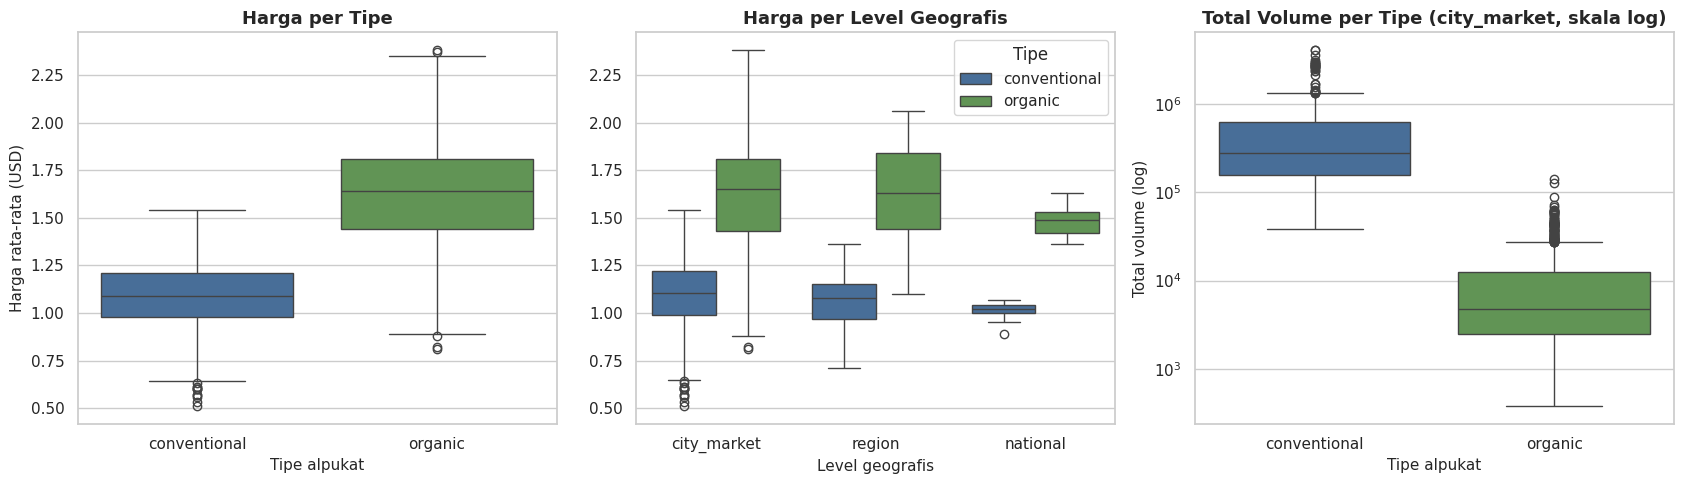

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# (a) Harga per tipe
sns.boxplot(data=df, x="avocado_type", y="average_price", hue="avocado_type",
            palette=PALETTE, legend=False, ax=axes[0])
axes[0].set_title("Harga per Tipe")
axes[0].set_xlabel("Tipe alpukat"); axes[0].set_ylabel("Harga rata-rata (USD)")

# (b) Harga per level geografis
sns.boxplot(data=df, x="geo_level", y="average_price", hue="avocado_type",
            palette=PALETTE, ax=axes[1])
axes[1].set_title("Harga per Level Geografis")
axes[1].set_xlabel("Level geografis"); axes[1].set_ylabel("")
axes[1].legend(title="Tipe")

# (c) Volume per tipe (log)
sns.boxplot(data=df_city, x="avocado_type", y="total_volume", hue="avocado_type",
            palette=PALETTE, legend=False, ax=axes[2])
axes[2].set_yscale("log")
axes[2].set_title("Total Volume per Tipe (city_market, skala log)")
axes[2].set_xlabel("Tipe alpukat"); axes[2].set_ylabel("Total volume (log)")

plt.tight_layout()
plt.show()

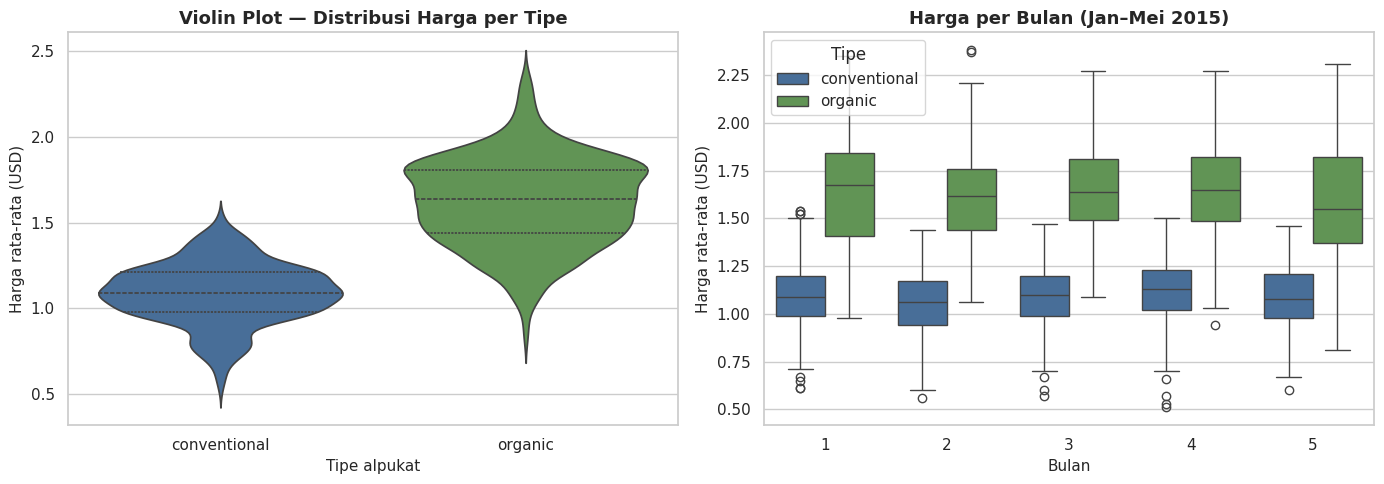

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Violin plot: bentuk distribusi harga per tipe
sns.violinplot(data=df, x="avocado_type", y="average_price", hue="avocado_type",
               palette=PALETTE, inner="quartile", legend=False, ax=axes[0])
axes[0].set_title("Violin Plot — Distribusi Harga per Tipe")
axes[0].set_xlabel("Tipe alpukat"); axes[0].set_ylabel("Harga rata-rata (USD)")

# Boxplot harga per bulan
sns.boxplot(data=df, x="month", y="average_price", hue="avocado_type",
            palette=PALETTE, ax=axes[1])
axes[1].set_title("Harga per Bulan (Jan–Mei 2015)")
axes[1].set_xlabel("Bulan"); axes[1].set_ylabel("Harga rata-rata (USD)")
axes[1].legend(title="Tipe")

plt.tight_layout()
plt.show()

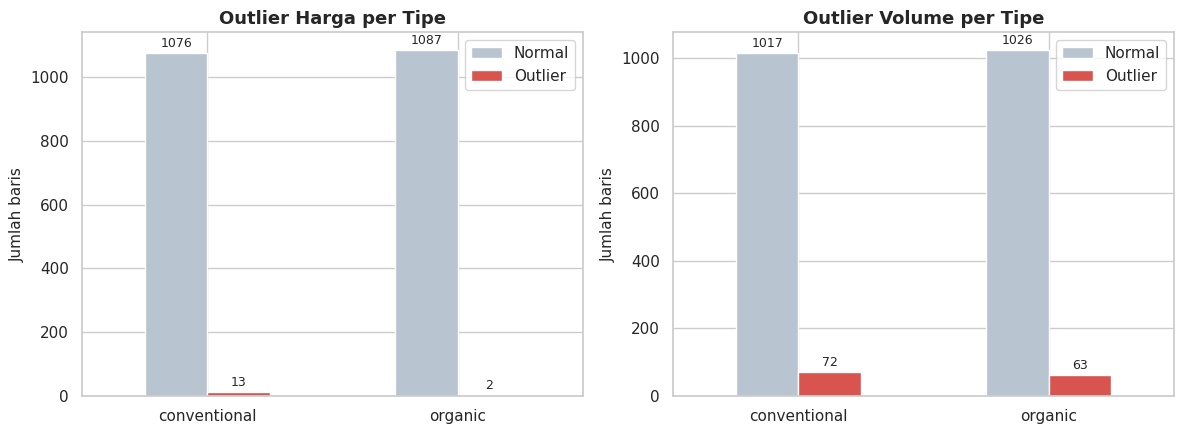

In [12]:
# Visualisasi flag outlier yang sudah ada di dataset
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for ax, kol, judul in zip(axes, ["price_outlier", "volume_outlier"],
                          ["Outlier Harga", "Outlier Volume"]):
    tab = pd.crosstab(df["avocado_type"], df[kol])
    tab.columns = ["Normal" if c is False or c == False else "Outlier" for c in tab.columns]
    tab.plot(kind="bar", ax=ax, color=["#B8C4D0", "#D9534F"], rot=0)
    ax.set_title(f"{judul} per Tipe")
    ax.set_xlabel(""); ax.set_ylabel("Jumlah baris")
    for c in ax.containers:
        ax.bar_label(c, padding=2, fontsize=9)

plt.tight_layout()
plt.show()

## 8. Scatter Plot — Hubungan Harga dan Volume

Hipotesis ekonomi dasar: semakin tinggi harga, semakin rendah volume yang terjual (hubungan negatif).

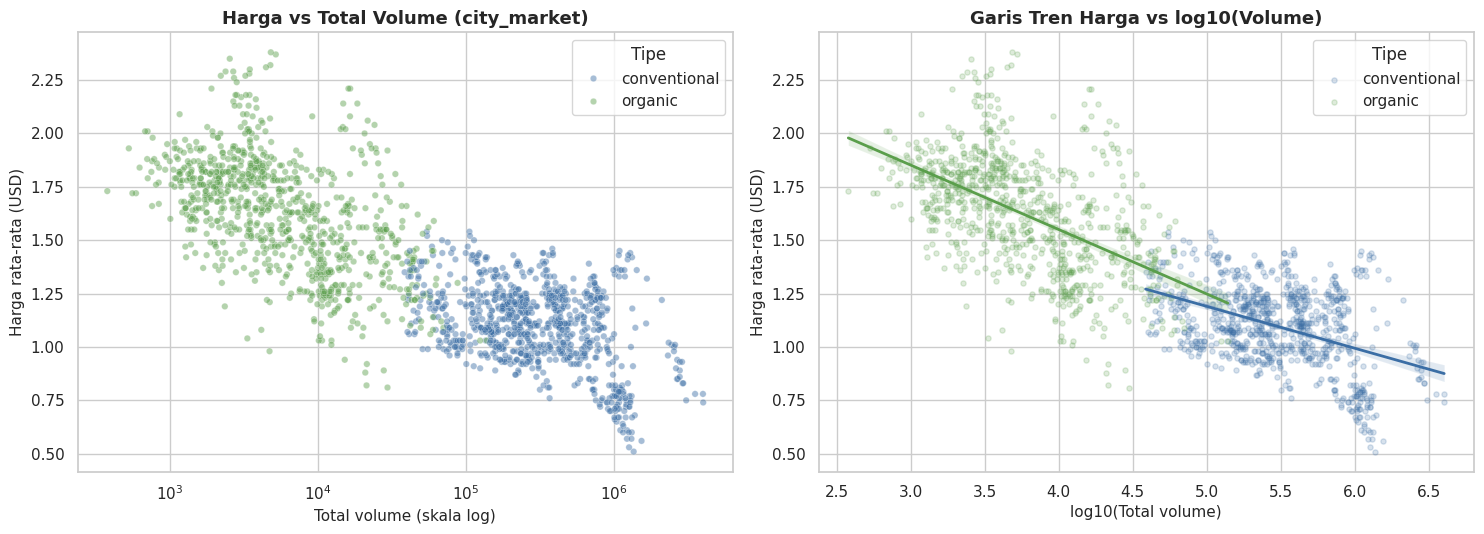

Korelasi harga vs log10(volume):
avocado_type
conventional   -0.432
organic        -0.532
dtype: float64


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# (a) Harga vs total volume (log), warna = tipe
sns.scatterplot(data=df_city, x="total_volume", y="average_price", hue="avocado_type",
                palette=PALETTE, alpha=0.45, s=22, ax=axes[0])
axes[0].set_xscale("log")
axes[0].set_title("Harga vs Total Volume (city_market)")
axes[0].set_xlabel("Total volume (skala log)")
axes[0].set_ylabel("Harga rata-rata (USD)")
axes[0].legend(title="Tipe")

# (b) Dengan garis regresi per tipe (pada log10 volume)
df_city["log_volume"] = np.log10(df_city["total_volume"].clip(lower=1))
for tipe, warna in PALETTE.items():
    sub = df_city[df_city["avocado_type"] == tipe]
    sns.regplot(data=sub, x="log_volume", y="average_price", color=warna,
                scatter_kws=dict(alpha=0.2, s=14), line_kws=dict(lw=2), ax=axes[1], label=tipe)
axes[1].set_title("Garis Tren Harga vs log10(Volume)")
axes[1].set_xlabel("log10(Total volume)")
axes[1].set_ylabel("Harga rata-rata (USD)")
axes[1].legend(title="Tipe")

plt.tight_layout()
plt.show()

# Korelasi (Pearson) harga vs log volume per tipe
print("Korelasi harga vs log10(volume):")
print(df_city.groupby("avocado_type").apply(lambda g: g["average_price"].corr(g["log_volume"])).round(3))

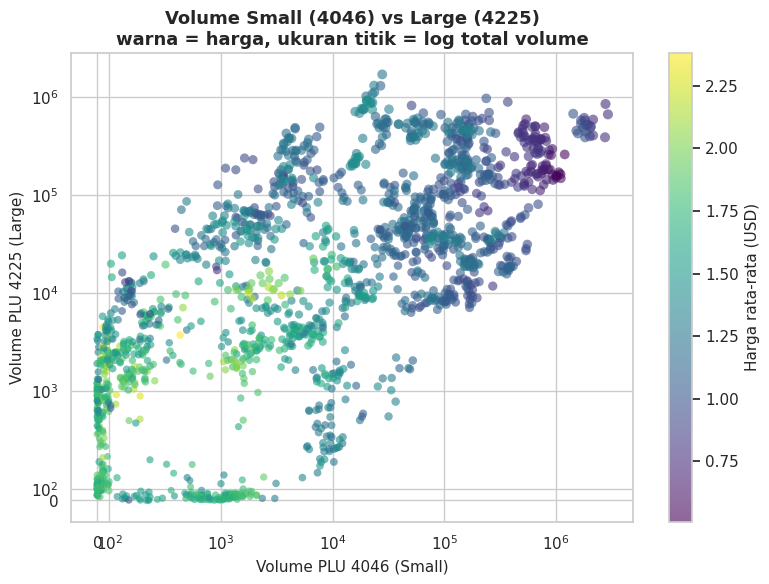

In [14]:
# Scatter: hubungan volume ukuran Small vs Large (bubble = total volume)
fig, ax = plt.subplots(figsize=(8, 6))
sc = ax.scatter(df_city["plu_4046_small"], df_city["plu_4225_large"],
                c=df_city["average_price"], s=np.log10(df_city["total_volume"].clip(lower=10))*8,
                cmap="viridis", alpha=0.6, edgecolor="none")
ax.set_xscale("symlog", linthresh=1e3); ax.set_yscale("symlog", linthresh=1e3)
ax.set_title("Volume Small (4046) vs Large (4225)\nwarna = harga, ukuran titik = log total volume")
ax.set_xlabel("Volume PLU 4046 (Small)"); ax.set_ylabel("Volume PLU 4225 (Large)")
plt.colorbar(sc, label="Harga rata-rata (USD)")
plt.tight_layout()
plt.show()

## 9. Line Chart — Tren Mingguan

Karena data hanya mencakup Januari–Mei 2015, tren dilihat per minggu. Level `national` dipakai agar tidak ada double counting.

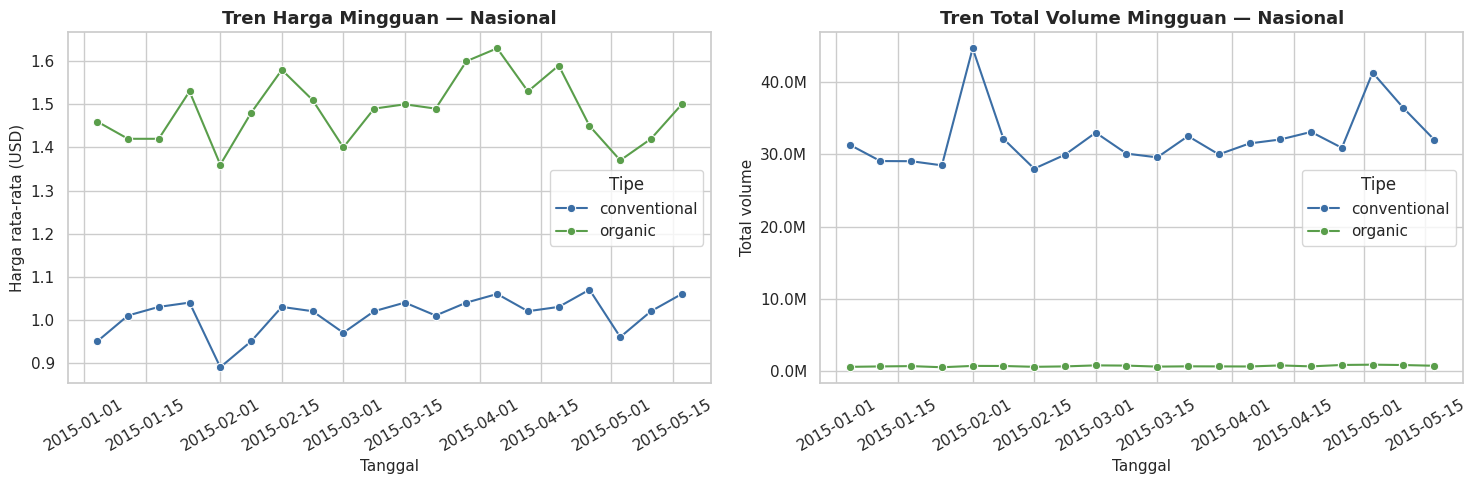

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# (a) Tren harga mingguan nasional
sns.lineplot(data=df_nat, x="date", y="average_price", hue="avocado_type",
             palette=PALETTE, marker="o", ax=axes[0])
axes[0].set_title("Tren Harga Mingguan — Nasional")
axes[0].set_xlabel("Tanggal"); axes[0].set_ylabel("Harga rata-rata (USD)")
axes[0].legend(title="Tipe")
axes[0].tick_params(axis="x", rotation=30)

# (b) Tren total volume mingguan nasional
sns.lineplot(data=df_nat, x="date", y="total_volume", hue="avocado_type",
             palette=PALETTE, marker="o", ax=axes[1])
axes[1].set_title("Tren Total Volume Mingguan — Nasional")
axes[1].set_xlabel("Tanggal"); axes[1].set_ylabel("Total volume")
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1e6:.1f}M"))
axes[1].legend(title="Tipe")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

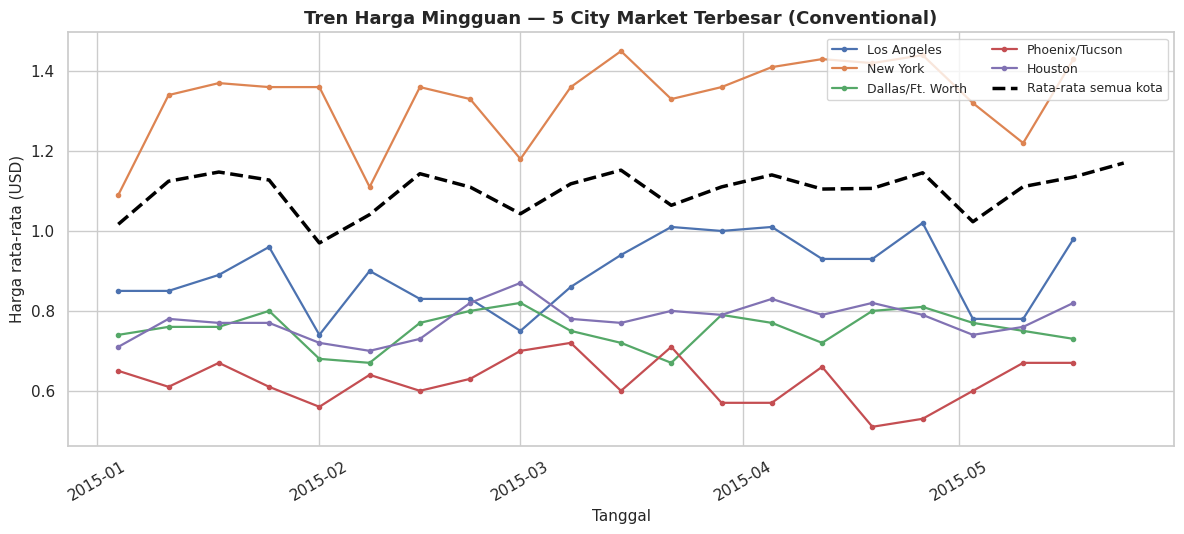

In [16]:
# Tren harga beberapa city market besar (conventional) + rata-rata semua city market
kota_besar = df_city.groupby("region")["total_volume"].sum().nlargest(5).index.tolist()
conv = df_city[df_city["avocado_type"] == "conventional"]

fig, ax = plt.subplots(figsize=(12, 5.5))
for kota in kota_besar:
    d = conv[conv["region"] == kota].sort_values("date")
    ax.plot(d["date"], d["average_price"], marker=".", lw=1.6, label=kota)
rata = conv.groupby("date")["average_price"].mean()
ax.plot(rata.index, rata.values, color="black", lw=2.5, ls="--", label="Rata-rata semua kota")
ax.set_title("Tren Harga Mingguan — 5 City Market Terbesar (Conventional)")
ax.set_xlabel("Tanggal"); ax.set_ylabel("Harga rata-rata (USD)")
ax.legend(ncol=2, fontsize=9)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

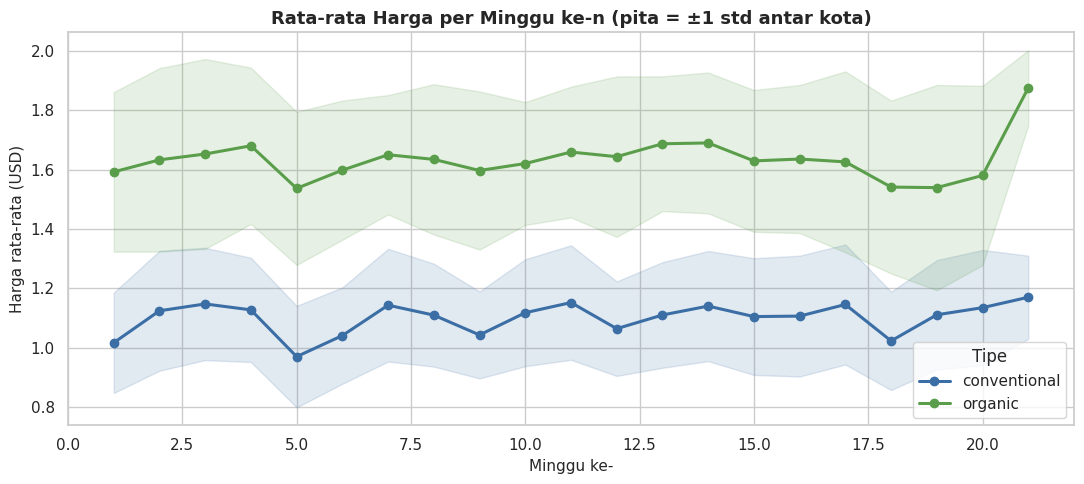

In [17]:
# Rata-rata harga per minggu ke-n (week_of_year) dengan pita sebaran (std)
mingguan = (df_city.groupby(["avocado_type", "week_of_year"])["average_price"]
            .agg(["mean", "std"]).reset_index())

fig, ax = plt.subplots(figsize=(11, 5))
for tipe, warna in PALETTE.items():
    d = mingguan[mingguan["avocado_type"] == tipe]
    ax.plot(d["week_of_year"], d["mean"], color=warna, lw=2.2, marker="o", label=tipe)
    ax.fill_between(d["week_of_year"], d["mean"] - d["std"], d["mean"] + d["std"],
                    color=warna, alpha=0.15)
ax.set_title("Rata-rata Harga per Minggu ke-n (pita = ±1 std antar kota)")
ax.set_xlabel("Minggu ke-"); ax.set_ylabel("Harga rata-rata (USD)")
ax.legend(title="Tipe")
plt.tight_layout()
plt.show()

## 10. Heatmap — Korelasi dan Pola Wilayah × Waktu

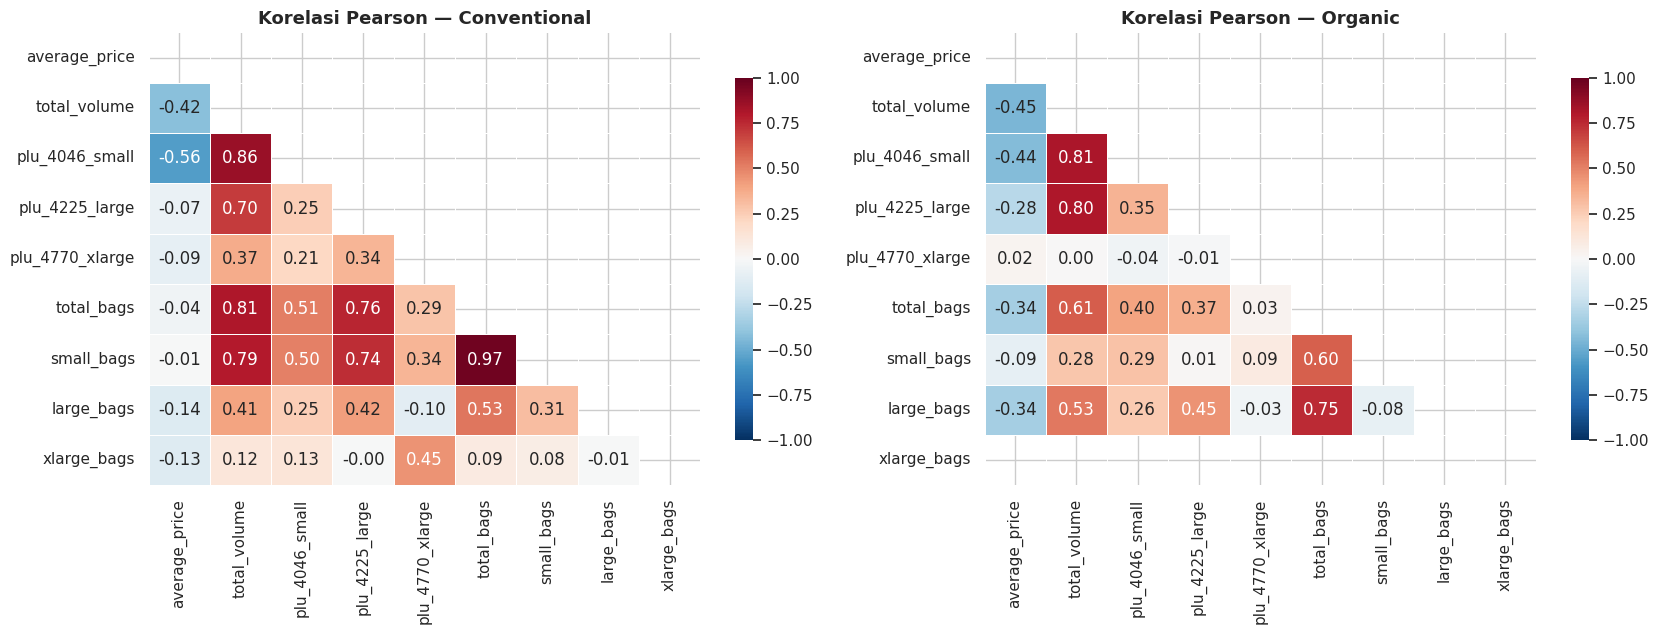

In [18]:
# (a) Heatmap korelasi variabel numerik utama (city_market)
kolom_num = ["average_price", "total_volume", "plu_4046_small", "plu_4225_large",
             "plu_4770_xlarge", "total_bags", "small_bags", "large_bags", "xlarge_bags"]

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
for ax, tipe in zip(axes, ["conventional", "organic"]):
    korelasi = df_city[df_city["avocado_type"] == tipe][kolom_num].corr()
    mask = np.triu(np.ones_like(korelasi, dtype=bool))
    sns.heatmap(korelasi, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
                vmin=-1, vmax=1, linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=ax)
    ax.set_title(f"Korelasi Pearson — {tipe.capitalize()}")
plt.tight_layout()
plt.show()

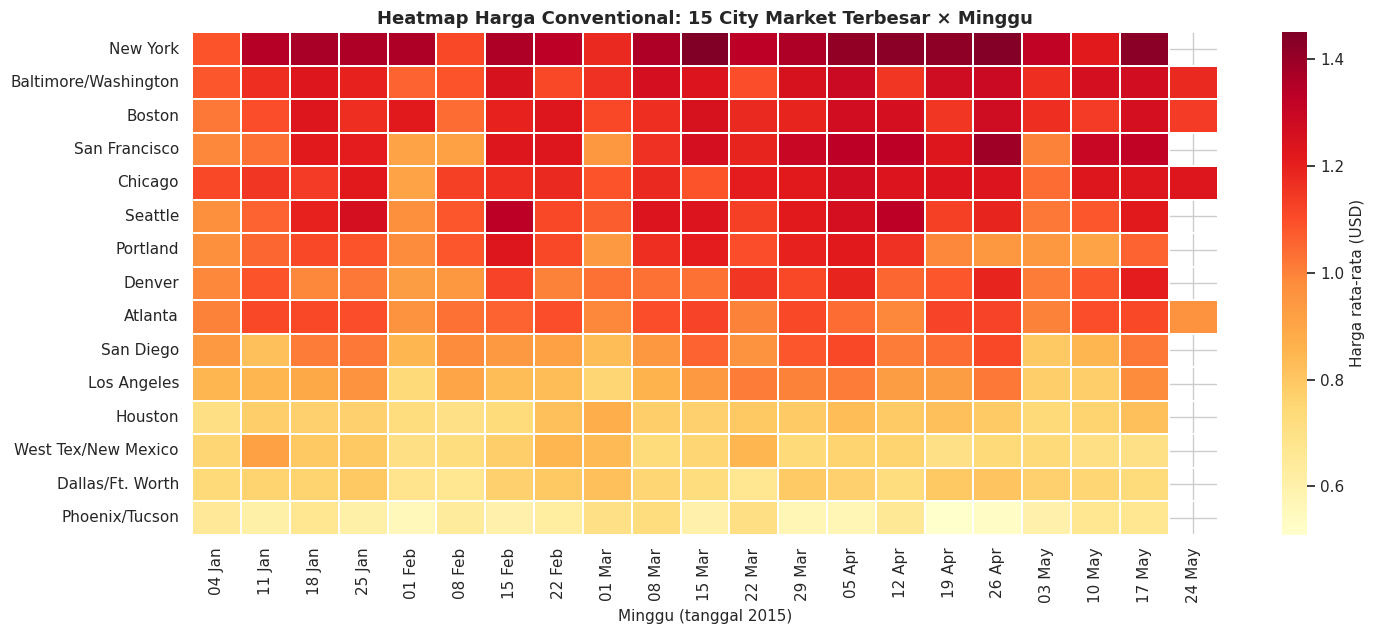

In [19]:
# (b) Heatmap harga: region (15 pasar terbesar) × tanggal, tipe conventional
top15 = df_city.groupby("region")["total_volume"].sum().nlargest(15).index
pivot = (df_city[(df_city["avocado_type"] == "conventional") & (df_city["region"].isin(top15))]
         .pivot_table(index="region", columns="date", values="average_price"))
pivot = pivot.loc[pivot.mean(axis=1).sort_values(ascending=False).index]
pivot.columns = [d.strftime("%d %b") for d in pivot.columns]

fig, ax = plt.subplots(figsize=(15, 6.5))
sns.heatmap(pivot, cmap="YlOrRd", annot=False, linewidths=0.3,
            cbar_kws={"label": "Harga rata-rata (USD)"}, ax=ax)
ax.set_title("Heatmap Harga Conventional: 15 City Market Terbesar × Minggu")
ax.set_xlabel("Minggu (tanggal 2015)"); ax.set_ylabel("")
plt.tight_layout()
plt.show()

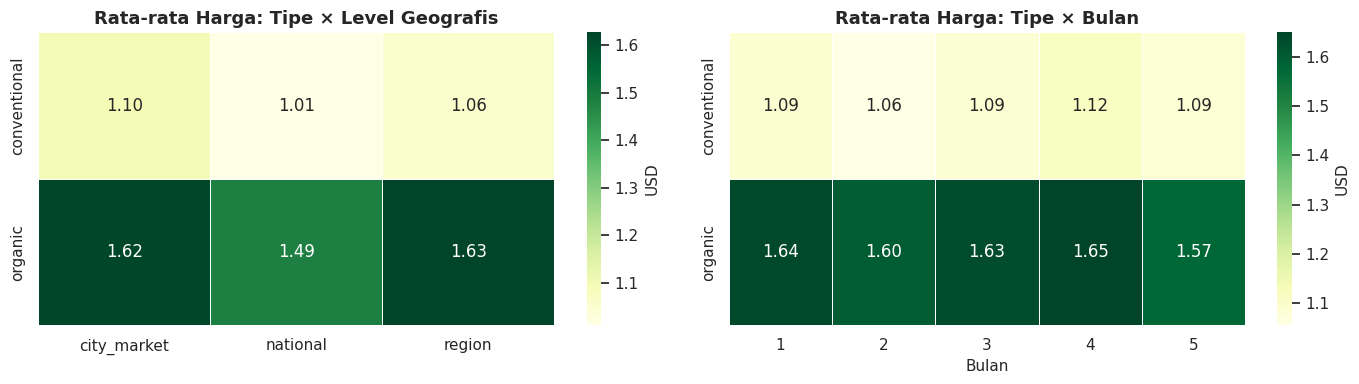

In [20]:
# (c) Heatmap rata-rata harga: tipe × level geografis, dan tipe × bulan
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

p1 = df.pivot_table(index="avocado_type", columns="geo_level", values="average_price", aggfunc="mean")
sns.heatmap(p1, annot=True, fmt=".2f", cmap="YlGn", linewidths=0.5, ax=axes[0],
            cbar_kws={"label": "USD"})
axes[0].set_title("Rata-rata Harga: Tipe × Level Geografis"); axes[0].set_xlabel(""); axes[0].set_ylabel("")

p2 = df.pivot_table(index="avocado_type", columns="month", values="average_price", aggfunc="mean")
sns.heatmap(p2, annot=True, fmt=".2f", cmap="YlGn", linewidths=0.5, ax=axes[1],
            cbar_kws={"label": "USD"})
axes[1].set_title("Rata-rata Harga: Tipe × Bulan"); axes[1].set_xlabel("Bulan"); axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

## 11. Pairplot — Eksplorasi Multivariat

Memberi gambaran cepat hubungan antar-variabel utama sekaligus (memakai sampel city_market, volume dalam log10).

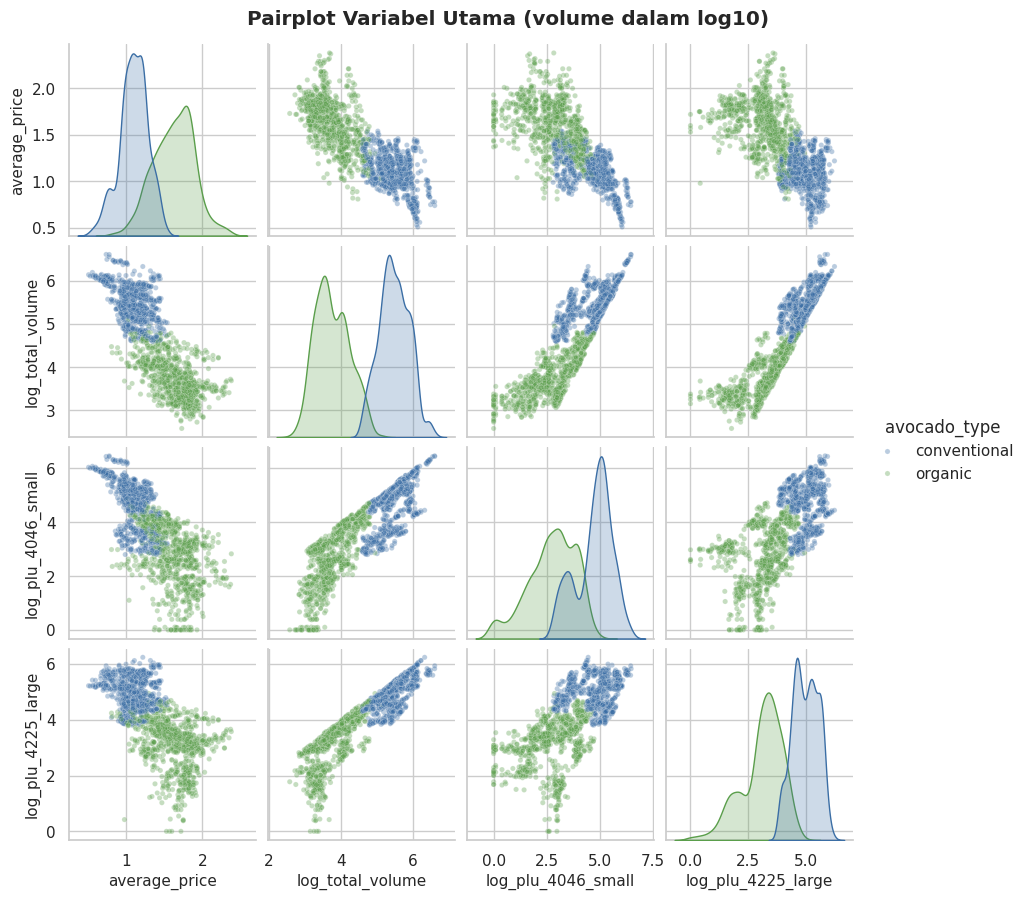

In [21]:
sub = df_city[["average_price", "total_volume", "plu_4046_small", "plu_4225_large",
               "avocado_type"]].copy()
for k in ["total_volume", "plu_4046_small", "plu_4225_large"]:
    sub[f"log_{k}"] = np.log10(sub[k].clip(lower=1))
sub = sub[["average_price", "log_total_volume", "log_plu_4046_small", "log_plu_4225_large", "avocado_type"]]

g = sns.pairplot(sub, hue="avocado_type", palette=PALETTE, diag_kind="kde",
                 plot_kws=dict(alpha=0.35, s=14), height=2.2)
g.fig.suptitle("Pairplot Variabel Utama (volume dalam log10)", y=1.02, fontweight="bold")
plt.show()

## 12. Visualisasi Interaktif (Plotly)

Grafik berikut dapat di-*hover*, di-*zoom*, dan difilter dengan klik legenda.

In [22]:
import plotly.express as px

# Scatter interaktif harga vs volume
fig = px.scatter(df_city, x="total_volume", y="average_price", color="avocado_type",
                 color_discrete_map=PALETTE, log_x=True, opacity=0.6,
                 hover_data=["region", "date"],
                 labels={"total_volume": "Total volume (log)", "average_price": "Harga (USD)",
                         "avocado_type": "Tipe"},
                 title="Harga vs Volume (interaktif)")
fig.update_layout(template="plotly_white", height=520)
fig.show()

In [23]:
# Line chart interaktif: pilih kota lewat legenda
fig = px.line(df_city.sort_values("date"), x="date", y="average_price", color="region",
              facet_col="avocado_type",
              labels={"date": "Tanggal", "average_price": "Harga (USD)", "region": "Region"},
              title="Tren Harga Mingguan per City Market (klik legenda untuk filter)")
fig.update_layout(template="plotly_white", height=560)
fig.show()